In [2]:
import os, time, json, math, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.transforms import v2 as T
import torchvision.transforms.functional as TF
from sklearn.metrics import confusion_matrix

try:
    display
except NameError:          # allows running the code outside Jupyter
    display = print

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # quick functional test with fake data; keep False for real runs

DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"
DATA_SEED   = 42        # fixed seed: which 500 images form train_small and the 400/100 split
CORRUPT_SEED = 2024     # fixed seed: shifted-test corruption pipeline
SEEDS       = [0, 1, 2] # 3 training seeds -> mean ± std
EPOCHS      = 2 if SMOKE_TEST else 60
BATCH_SIZE  = 32
PATIENCE    = 20        # early stopping on validation accuracy
NUM_WORKERS = 0 if SMOKE_TEST else 2
OUT_DIR, CKPT_DIR = "outputs", "checkpoints"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(CKPT_DIR, exist_ok=True)

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Device:", DEVICE, "| torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| SMOKE_TEST =", SMOKE_TEST)

Device: cuda | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | SMOKE_TEST = False


In [3]:
if not SMOKE_TEST:
    train_full = torchvision.datasets.CIFAR10("./data", train=True,  download=True)
    test_full  = torchvision.datasets.CIFAR10("./data", train=False, download=True)
    X_all = torch.from_numpy(train_full.data).permute(0, 3, 1, 2).contiguous()   # uint8 N×3×32×32
    y_all = torch.tensor(train_full.targets)
    X_test_clean = torch.from_numpy(test_full.data).permute(0, 3, 1, 2).contiguous()
    y_test = torch.tensor(test_full.targets)
else:   # fake data with the same shapes, only to check that the code runs
    g = torch.Generator().manual_seed(0)
    X_all = torch.randint(0, 256, (2000, 3, 32, 32), dtype=torch.uint8, generator=g); y_all = torch.arange(2000) % 10
    X_test_clean = torch.randint(0, 256, (300, 3, 32, 32), dtype=torch.uint8, generator=g); y_test = torch.arange(300) % 10

# --- fixed selection of 50 images per class, then 40/10 split -------------------------
rng = np.random.default_rng(DATA_SEED)
train_idx, val_idx = [], []
for c in range(10):
    idx = np.where(y_all.numpy() == c)[0]
    chosen = rng.choice(idx, size=50, replace=False)
    train_idx += chosen[:40].tolist(); val_idx += chosen[40:].tolist()

X_train = X_all[train_idx].float() / 255.;  y_train = y_all[train_idx]
X_val   = X_all[val_idx].float() / 255.;    y_val   = y_all[val_idx]
json.dump({"train_idx": train_idx, "val_idx": val_idx}, open(f"{OUT_DIR}/train_small_indices.json", "w"))

# per-channel normalisation statistics computed on the 400 training images only
MEAN = X_train.mean(dim=(0, 2, 3)); STD = X_train.std(dim=(0, 2, 3))
print("train:", tuple(X_train.shape), "val:", tuple(X_val.shape), "test:", tuple(X_test_clean.shape))
print("class counts train:", torch.bincount(y_train).tolist(), " val:", torch.bincount(y_val).tolist())
print("mean:", MEAN.numpy().round(3), "std:", STD.numpy().round(3))

100%|██████████| 170M/170M [29:02<00:00, 97.8kB/s]


train: (400, 3, 32, 32) val: (100, 3, 32, 32) test: (10000, 3, 32, 32)
class counts train: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40]  val: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
mean: [0.481 0.471 0.435] std: [0.242 0.239 0.259]


In [ ]:

# the set is generated once with fix seed

SHIFTED_FILE = "shifted_test.npz"   

PERMS = [(0, 2, 1), (1, 0, 2), (1, 2, 0), (2, 0, 1), (2, 1, 0)]  

def hidden_corruption(img, rng):
    # unlisted corruption: swap the colour channels
    perm = PERMS[rng.integers(len(PERMS))]
    return img[list(perm)], perm

def corrupt(img, rng, use_hidden=True):
    # img: float tensor 3×32×32 in [0,1]  ->  corrupted image + dict of parameters
    m = {}
    m["angle"] = float(rng.uniform(-25, 25))
    img = TF.rotate(img, m["angle"], interpolation=T.InterpolationMode.BILINEAR, fill=0.0)
    m["brightness"] = float(rng.uniform(0.5, 1.5)); m["contrast"] = float(rng.uniform(0.6, 1.4))
    img = TF.adjust_contrast(TF.adjust_brightness(img, m["brightness"]), m["contrast"])
    m["blur"] = bool(rng.random() < 0.3)
    if m["blur"]:
        s = float(rng.uniform(0.5, 1.2)); img = TF.gaussian_blur(img, [3, 3], [s, s])
    m["noise"] = bool(rng.random() < 0.3)
    if m["noise"]:
        sd = float(rng.uniform(0.02, 0.08))
        img = img + torch.from_numpy(rng.normal(0, sd, img.shape)).float()
    area = rng.uniform(0.18, 0.30) * 32 * 32; ar = rng.uniform(0.5, 2.0)
    h = int(min(32, round(math.sqrt(area * ar)))); w = int(min(32, round(math.sqrt(area / ar))))
    y0 = int(rng.integers(0, 32 - h + 1)); x0 = int(rng.integers(0, 32 - w + 1))
    img = img.clone(); img[:, y0:y0 + h, x0:x0 + w] = float(rng.uniform(0, 1))
    m.update(occ_box=(y0, x0, h, w), occ_frac=h * w / 1024)
    m["channel_swap"] = False
    if use_hidden and rng.random() < 0.5:
        img, perm = hidden_corruption(img, rng); m["channel_swap"] = True; m["perm"] = perm
    return img.clamp(0, 1), m

def to_uint8(x): return (x.clamp(0, 1) * 255).round().to(torch.uint8)

shift_meta = None
if os.path.exists(SHIFTED_FILE):
    d = np.load(SHIFTED_FILE); X_shift = torch.from_numpy(d["X"]); y_shift = torch.from_numpy(d["y"]).long()
    if X_shift.shape[-1] == 3: X_shift = X_shift.permute(0, 3, 1, 2).contiguous()
    print("Loaded instructor shifted_test:", tuple(X_shift.shape))
else:
    rng_c = np.random.default_rng(CORRUPT_SEED)
    out, metas = [], []
    t0 = time.time()
    for i in range(len(X_test_clean)):
        img, m = corrupt(X_test_clean[i].float() / 255., rng_c); out.append(to_uint8(img)); metas.append(m)
    X_shift, y_shift = torch.stack(out), y_test.clone()
    shift_meta = pd.DataFrame(metas)
    print(f"Generated shifted_test {tuple(X_shift.shape)} in {time.time()-t0:.1f}s")
    display(shift_meta[["angle", "brightness", "contrast", "blur", "noise", "occ_frac", "channel_swap"]]
            .astype(float).describe().T.round(3))

Generated shifted_test (10000, 3, 32, 32) in 9.8s


,count,mean,std,min,25%,50%,75%,max
angle,10000.0,-0.034,14.421,-24.992,-12.718,0.240,12.356,24.988
brightness,10000.0,0.999,0.286,0.500,0.752,0.999,1.249,1.500
contrast,10000.0,1.000,0.232,0.600,0.799,1.000,1.200,1.400
blur,10000.0,0.299,0.458,0.000,0.000,0.000,1.000,1.000
noise,10000.0,0.300,0.458,0.000,0.000,0.000,1.000,1.000
occ_frac,10000.0,0.240,0.036,0.172,0.211,0.241,0.270,0.317
channel_swap,10000.0,0.509,0.500,0.000,0.000,1.000,1.000,1.000


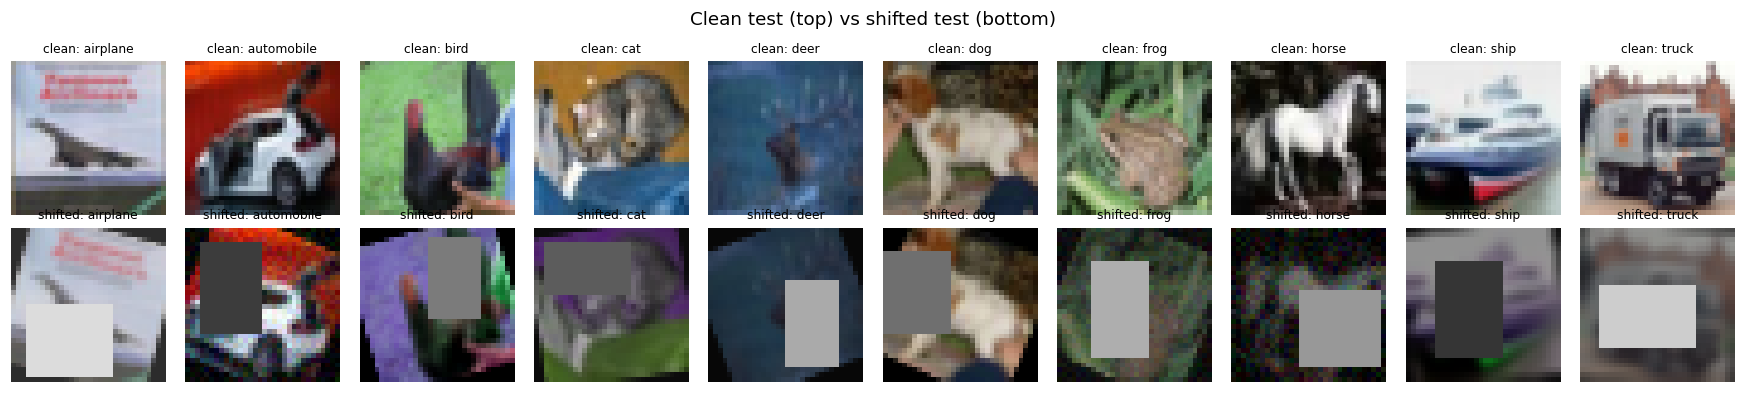

In [5]:
def show_grid(imgs, titles=None, nrow=2, ncol=10, figsize=(16, 3.6), suptitle=None, fname=None):
    fig, axes = plt.subplots(nrow, ncol, figsize=figsize)
    for k, ax in enumerate(axes.flat):
        ax.axis("off")
        if k < len(imgs):
            im = imgs[k]; im = im.float() / 255. if im.dtype == torch.uint8 else im
            ax.imshow(im.permute(1, 2, 0).clamp(0, 1).numpy())
            if titles: ax.set_title(titles[k], fontsize=8)
    if suptitle: fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    if fname: plt.savefig(f"{OUT_DIR}/{fname}", bbox_inches="tight")
    plt.show()

idx = [int(np.where(y_test.numpy() == c)[0][0]) for c in range(10)]
show_grid([X_test_clean[i] for i in idx] + [X_shift[i] for i in idx],
          [f"clean: {CLASSES[y_test[i]]}" for i in idx] + [f"shifted: {CLASSES[y_test[i]]}" for i in idx],
          suptitle="Clean test (top) vs shifted test (bottom)", fname="clean_vs_shifted.png")

In [ ]:
# miniinception net with <1M parameter

class ConvBNReLU(nn.Sequential):
    def __init__(self, cin, cout, k, stride=1):
        super().__init__(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Inception(nn.Module):
    # parallel 1×1, 1×1→3×3, 1×1→5×5 and maxpool→1×1 branches, concatenated on channels
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = ConvBNReLU(cin, c1, 1)
        self.b3 = nn.Sequential(ConvBNReLU(cin, c3r, 1), ConvBNReLU(c3r, c3, 3))
        self.b5 = nn.Sequential(ConvBNReLU(cin, c5r, 1), ConvBNReLU(c5r, c5, 5))
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), ConvBNReLU(cin, cp, 1))
        self.out_ch = c1 + c3 + c5 + cp
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)

class MiniInceptionNet(nn.Module):
    def __init__(self, mean, std, num_classes=10, drop=0.3):
        super().__init__()
        self.register_buffer("mean", mean.view(1, 3, 1, 1).clone())
        self.register_buffer("std", std.view(1, 3, 1, 1).clone())
        self.stem = nn.Sequential(ConvBNReLU(3, 48, 3), ConvBNReLU(48, 64, 3), nn.MaxPool2d(2))
        self.inc3a = Inception(64, 32, 48, 64, 8, 16, 16)
        self.inc3b = Inception(self.inc3a.out_ch, 48, 64, 96, 16, 32, 32)
        self.pool = nn.MaxPool2d(2)
        self.inc4a = Inception(self.inc3b.out_ch, 64, 64, 128, 16, 32, 32)
        self.inc4b = Inception(self.inc4a.out_ch, 80, 80, 128, 16, 48, 48)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(self.inc4b.out_ch, 128),
                                  nn.ReLU(inplace=True), nn.Dropout(drop), nn.Linear(128, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.stem(x)
        x = self.inc3b(self.inc3a(x))
        x = self.pool(x)
        x = self.inc4b(self.inc4a(x))
        return self.head(self.gap(x))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m = MiniInceptionNet(MEAN, STD)
rows = [(n, count_params(c)) for n, c in _m.named_children()]
display(pd.DataFrame(rows + [("TOTAL", count_params(_m))], columns=["block", "trainable params"]))
assert count_params(_m) <= 1_000_000, "Model exceeds the 1M parameter limit!"
print(f"Total trainable parameters: {count_params(_m):,}  (limit 1,000,000)")
with torch.no_grad(): print("output shape:", tuple(_m(torch.rand(2, 3, 32, 32)).shape))

,block,trainable params
0,stem,29168
1,inc3a,37872
2,inc3b,89152
3,pool,0
4,inc4a,123808
5,inc4b,169504
6,gap,0
7,head,40330
8,TOTAL,489834


Total trainable parameters: 489,834  (limit 1,000,000)
output shape: (2, 10)


In [ ]:
# augmentations, training loop and evaluation all augmentations run on the fly inside the Dataset per-image or inside the training loop



class AddGaussianNoise(nn.Module):
    def __init__(self, std=(0.01, 0.06)):
        super().__init__(); self.std = std
    def forward(self, x):
        return (x + torch.randn_like(x) * random.uniform(*self.std)).clamp(0, 1)

def geometric():
    return [T.RandomCrop(32, padding=4, padding_mode="reflect"),
            T.RandomHorizontalFlip(),
            T.RandomAffine(degrees=30, translate=(0.05, 0.05), scale=(0.9, 1.1))]

def photometric():
    return [T.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5, hue=0.05),
            T.RandomApply([T.GaussianBlur(3, sigma=(0.1, 1.5))], p=0.3),
            T.RandomApply([AddGaussianNoise()], p=0.3)]

def erasing():
    return [T.RandomErasing(p=0.5, scale=(0.05, 0.3), ratio=(0.3, 3.3), value="random")]

# Ablation configurations (each "tf" is a function so every run builds fresh transform objects)
CONFIGS = {
    "No augmentation":                      dict(tf=lambda: [],                                 mix=False, ls=0.0),
    "Geometric only (crop, flip, rotation)": dict(tf=geometric,                                  mix=False, ls=0.0),
    "Photometric only (color jitter, blur, noise)": dict(tf=photometric,                         mix=False, ls=0.0),
    "Geometric + photometric":              dict(tf=lambda: geometric() + photometric(),        mix=False, ls=0.0),
    "+ Cutout / Random Erasing":            dict(tf=lambda: geometric() + photometric() + erasing(), mix=False, ls=0.0),
    "+ Mixup/CutMix + label smoothing":     dict(tf=lambda: geometric() + photometric() + erasing(), mix=True, ls=0.1),
    "Final model":                          dict(tf=lambda: geometric() + photometric() + [T.RandomGrayscale(p=0.2)] + erasing(),
                                                 mix=True, ls=0.1),
}
CFG_NAMES = list(CONFIGS)

class AugDataset(Dataset):
    def __init__(self, X, y, tf=None): self.X, self.y, self.tf = X, y, tf
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x = self.X[i]
        return (self.tf(x) if self.tf is not None else x), self.y[i]

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32; np.random.seed(s); random.seed(s)

def make_loader(X, y, tf, seed):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(AugDataset(X, y, tf), batch_size=BATCH_SIZE, shuffle=True, drop_last=False,
                      num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=g,
                      pin_memory=(DEVICE == "cuda"), persistent_workers=NUM_WORKERS > 0)

def mix_batch(x, y, rng, alpha=1.0, p=0.8):
    # per batch: with prob p apply Mixup or CutMix (50/50). Returns x, y_a, y_b, lambda
    if rng.random() > p: return x, y, y, 1.0
    lam = float(rng.beta(alpha, alpha)); perm = torch.randperm(x.size(0), device=x.device)
    if rng.random() < 0.5:                                    # CutMix
        H, W = x.shape[2:]; r = math.sqrt(1 - lam)
        ch, cw = int(H * r), int(W * r); cy, cx = int(rng.integers(H)), int(rng.integers(W))
        y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H); x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
        x = x.clone(); x[:, :, y1:y2, x1:x2] = x[perm, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
    else:                                                     # Mixup
        x = lam * x + (1 - lam) * x[perm]
    return x, y, y[perm], lam

@torch.no_grad()
def evaluate(model, X, y, bs=500, tta_fn=None):
    # returns accuracy (%), mean CE loss, predictions, softmax probabilities
    model.eval(); probs = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]; xb = (xb.float() / 255. if xb.dtype == torch.uint8 else xb).to(DEVICE)
        p = tta_fn(model, xb) if tta_fn else F.softmax(model(xb), 1)
        probs.append(p.cpu())
    probs = torch.cat(probs); preds = probs.argmax(1)
    loss = F.nll_loss(torch.log(probs.clamp_min(1e-12)), y).item()
    return 100 * (preds == y).float().mean().item(), loss, preds, probs

def build_optimizer(model, lr, wd):
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        (no_decay if p.ndim == 1 else decay).append(p)       # no weight decay on BN params and biases
    return torch.optim.SGD([{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0}],
                           lr=lr, momentum=0.9, nesterov=True)

def train_model(cfg_name, seed, lr, wd, epochs=EPOCHS, verbose=False):
    cfg = CONFIGS[cfg_name]; set_seed(seed)
    tfs = cfg["tf"](); tf = T.Compose(tfs) if tfs else None
    loader = make_loader(X_train, y_train, tf, seed)
    model = MiniInceptionNet(MEAN, STD).to(DEVICE)
    opt = build_optimizer(model, lr, wd)
    steps, warm = epochs * len(loader), 3 * len(loader)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
                                              else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["ls"])
    rng = np.random.default_rng(seed)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr"]}
    best = {"acc": -1, "loss": 1e9, "state": None, "epoch": 0}; bad = 0
    for ep in range(epochs):
        model.train(); tl = tc = n = 0
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            if cfg["mix"]: x, ya, yb, lam = mix_batch(x, y, rng)
            else: ya, yb, lam = y, y, 1.0
            out = model(x)
            loss = lam * crit(out, ya) + (1 - lam) * crit(out, yb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            pred = out.argmax(1)
            tl += loss.item() * x.size(0); n += x.size(0)
            tc += (lam * (pred == ya).float() + (1 - lam) * (pred == yb).float()).sum().item()
        va, vl, _, _ = evaluate(model, X_val, y_val)
        for k, v in zip(hist, [tl / n, 100 * tc / n, vl, va, opt.param_groups[0]["lr"]]): hist[k].append(v)
        if va > best["acc"] or (va == best["acc"] and vl < best["loss"]):      # model selection on validation only
            best = {"acc": va, "loss": vl, "state": copy.deepcopy(model.state_dict()), "epoch": ep + 1}; bad = 0
        else:
            bad += 1
        if verbose and (ep + 1) % 10 == 0:
            print(f"  ep {ep+1:3d} | train loss {tl/n:.3f} acc {100*tc/n:5.1f} | val loss {vl:.3f} acc {va:5.1f}")
        if bad >= PATIENCE:
            if verbose: print(f"  early stop at epoch {ep+1}")
            break
    model.load_state_dict(best["state"])
    return model, hist, best["epoch"]

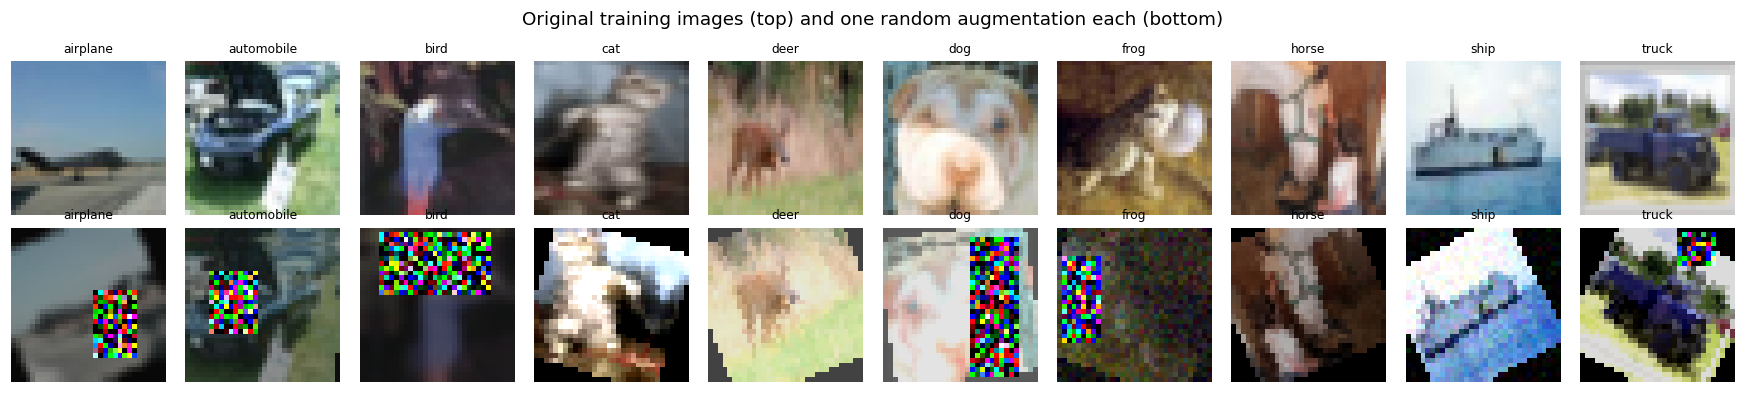

In [8]:
# Visual check of the on-the-fly augmentation (final configuration)
set_seed(0)
_tf = T.Compose(CONFIGS["Final model"]["tf"]())
imgs = [X_train[i] for i in range(0, 400, 40)]
show_grid(imgs + [_tf(im) for im in imgs], [CLASSES[y_train[i]] for i in range(0, 400, 40)] * 2,
          suptitle="Original training images (top) and one random augmentation each (bottom)", fname="augmentation_examples.png")

In [ ]:
# hyper parameter selection

LR_GRID = [0.025, 0.05, 0.1] if not SMOKE_TEST else [0.05]
WD_GRID = [5e-4, 2e-3]       if not SMOKE_TEST else [5e-4]
HP_FILE = f"{OUT_DIR}/hparam_search.json"
hp = json.load(open(HP_FILE)) if os.path.exists(HP_FILE) else []
done = {(r["lr"], r["wd"]) for r in hp}
for lr in LR_GRID:
    for wd in WD_GRID:
        if (lr, wd) in done: continue
        t0 = time.time()
        m, h, be = train_model("Geometric + photometric", seed=100, lr=lr, wd=wd)
        hp.append({"lr": lr, "wd": wd, "best_val_acc": max(h["val_acc"]), "best_epoch": be,
                   "final_val_loss": h["val_loss"][be - 1]})
        json.dump(hp, open(HP_FILE, "w"))
        print(f"lr={lr:<6} wd={wd:<7} -> best val acc {max(h['val_acc']):.1f}%  ({time.time()-t0:.0f}s)")
hp_df = pd.DataFrame(hp).sort_values(["best_val_acc", "final_val_loss"], ascending=[False, True])
display(hp_df)
LR, WD = float(hp_df.iloc[0]["lr"]), float(hp_df.iloc[0]["wd"])
print(f"Selected on validation: LR = {LR}, weight decay = {WD}")

lr=0.025  wd=0.0005  -> best val acc 46.0%  (50s)
lr=0.025  wd=0.002   -> best val acc 46.0%  (46s)
lr=0.05   wd=0.0005  -> best val acc 45.0%  (47s)
lr=0.05   wd=0.002   -> best val acc 47.0%  (47s)
lr=0.1    wd=0.0005  -> best val acc 36.0%  (46s)
lr=0.1    wd=0.002   -> best val acc 39.0%  (47s)


,lr,wd,best_val_acc,best_epoch,final_val_loss
3,0.050,0.0020,47.000000,59,1.505572
0,0.025,0.0005,46.000001,53,1.535983
1,0.025,0.0020,46.000001,41,1.628867
2,0.050,0.0005,44.999999,49,1.639736
5,0.100,0.0020,38.999999,52,1.639622
4,0.100,0.0005,36.000001,52,1.690576


Selected on validation: LR = 0.05, weight decay = 0.002


In [10]:
RES_FILE = f"{OUT_DIR}/results.json"
RESULTS = json.load(open(RES_FILE)) if os.path.exists(RES_FILE) else {}

def ckpt_path(cfg_name, seed):
    safe = "".join(ch if ch.isalnum() else "_" for ch in cfg_name)
    return f"{CKPT_DIR}/{safe}_seed{seed}.pt"

def run_config(cfg_name, seeds=SEEDS, verbose=True):
    # trains one configuration for all seeds; evaluates clean/shifted test ONCE after training. Resumable.
    RESULTS.setdefault(cfg_name, {})
    for s in seeds:
        if str(s) in RESULTS[cfg_name] and os.path.exists(ckpt_path(cfg_name, s)):
            print(f"[{cfg_name}] seed {s}: already done"); continue
        t0 = time.time()
        model, hist, be = train_model(cfg_name, s, LR, WD, verbose=False)
        tr_acc = evaluate(model, X_train, y_train)[0]            # clean training images, eval mode
        va_acc = evaluate(model, X_val, y_val)[0]
        cl_acc = evaluate(model, X_test_clean, y_test)[0]
        sh_acc = evaluate(model, X_shift, y_shift)[0]
        RESULTS[cfg_name][str(s)] = dict(train=tr_acc, val=va_acc, clean=cl_acc, shifted=sh_acc, best_epoch=be,
                                         hist=hist, time=time.time() - t0)
        torch.save(model.state_dict(), ckpt_path(cfg_name, s))
        json.dump(RESULTS, open(RES_FILE, "w"))
        if verbose:
            print(f"[{cfg_name}] seed {s}: train {tr_acc:5.1f} | val {va_acc:5.1f} | clean {cl_acc:5.2f} | "
                  f"shifted {sh_acc:5.2f} | best epoch {be} | {time.time()-t0:.0f}s")

def load_model(cfg_name, seed):
    m = MiniInceptionNet(MEAN, STD).to(DEVICE)
    m.load_state_dict(torch.load(ckpt_path(cfg_name, seed), map_location=DEVICE))
    return m.eval()

def summary_row(cfg_name, keys=("train", "val", "clean", "shifted")):
    r = RESULTS[cfg_name]; out = {"Configuration": cfg_name}
    for k in keys:
        v = np.array([r[s][k] for s in r]); out[k] = f"{v.mean():.2f} ± {v.std():.2f}"
    return out

def plot_curves(cfg_name, fname):
    hs = [RESULTS[cfg_name][s]["hist"] for s in RESULTS[cfg_name]]
    L = max(len(h["train_loss"]) for h in hs)
    def stack(k): return np.array([h[k] + [np.nan] * (L - len(h[k])) for h in hs])
    ep = np.arange(1, L + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for k, c in [("train", "tab:blue"), ("val", "tab:orange")]:
        for j, metric in enumerate(["loss", "acc"]):
            a = stack(f"{k}_{metric}"); mu, sd = np.nanmean(a, 0), np.nanstd(a, 0)
            ax[j].plot(ep, mu, c=c, label=f"{'Train' if k=='train' else 'Validation'} (mean of {len(hs)} seeds)")
            ax[j].fill_between(ep, mu - sd, mu + sd, color=c, alpha=0.2)
    ax[0].set(title=f"Loss: {cfg_name}", xlabel="Epoch", ylabel="Cross-entropy loss")
    ax[1].set(title=f"Accuracy: {cfg_name}", xlabel="Epoch", ylabel="Accuracy (%)")
    for a in ax: a.legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}", bbox_inches="tight"); plt.show()

[No augmentation] seed 0: train  99.5 | val  49.0 | clean 40.73 | shifted 17.44 | best epoch 38 | 17s
[No augmentation] seed 1: train 100.0 | val  55.0 | clean 43.98 | shifted 18.28 | best epoch 50 | 18s
[No augmentation] seed 2: train  98.3 | val  48.0 | clean 41.11 | shifted 19.28 | best epoch 33 | 16s


,Configuration,train,val,clean,shifted
0,No augmentation,99.25 ± 0.74,50.67 ± 3.09,41.94 ± 1.45,18.33 ± 0.75


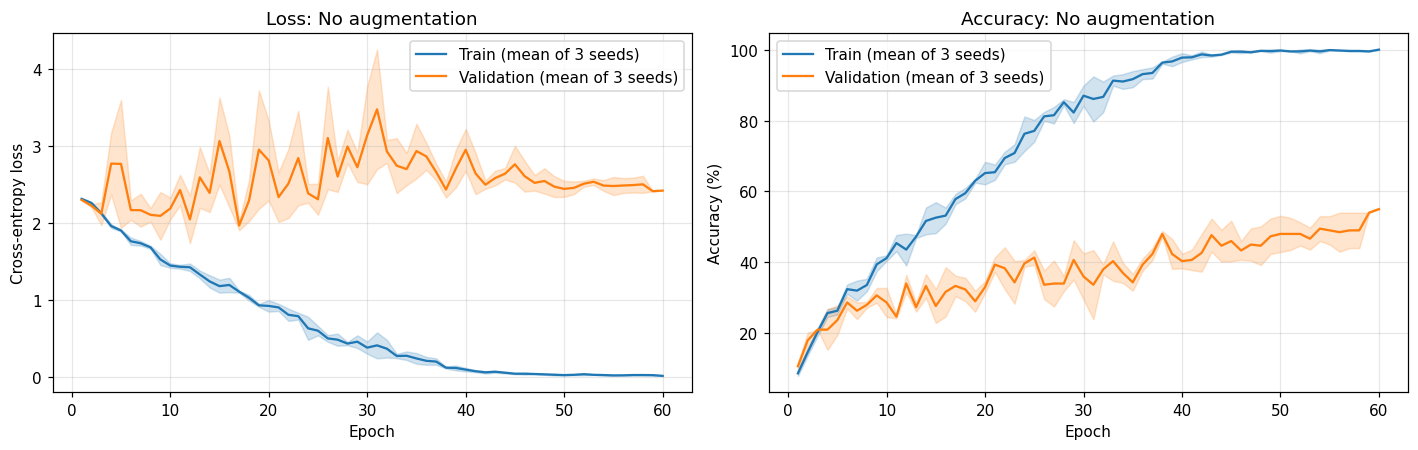

Train 99.3%  →  clean test 41.9%  (generalisation gap 57.3 pts)  →  shifted test 18.3%  (extra drop from corruption 23.6 pts)


In [ ]:
#part A

run_config("No augmentation")
display(pd.DataFrame([summary_row("No augmentation")]))
plot_curves("No augmentation", "partA_learning_curves.png")

r = RESULTS["No augmentation"]
tr, cl, sh = [np.mean([r[s][k] for s in r]) for k in ("train", "clean", "shifted")]
print(f"Train {tr:.1f}%  →  clean test {cl:.1f}%  (generalisation gap {tr-cl:.1f} pts)  →  "
      f"shifted test {sh:.1f}%  (extra drop from corruption {cl-sh:.1f} pts)")

**Diagnosis: both overfitting and covariate shift.**
Averaged over 3 seeds, the baseline reaches 99.25 % on train, 50.67 % on validation, 41.94 % on the clean test and only 18.33 % on the shifted test.
Training loss falls almost to zero while validation loss stays around 2.4 to 3.5, so the network has memorised the 400 images. That 57-point gap between train and clean test is overfitting.
The further 23.6-point drop from clean to shifted test is covariate shift: the labels are the same but the images look different (rotation, lighting, occlusion, colour), and nothing in training showed the model those changes.



## Part B: Augmentation strategy

I used only augmentations that match the kind of damage in the shifted test, applied on the fly to training images.

**Random crop, small shift and scale:** objects in CIFAR-10 are not always centred, so this teaches the model to find them anywhere in the image.

**Horizontal flip:** a car facing left is still a car, so this doubles the variety for free.

**Rotation ±30°:** slightly wider than the test's ±25°, so the whole test range is covered.

**Colour jitter:** random brightness, contrast and saturation changes, so the model does not depend on exact lighting or colour.

**Blur and noise:** used on some images so the model does not rely on fine texture.

**Random Erasing:** hides a random patch, just like the ~25% occlusion in the test, so the model learns to use the visible parts of the object.

**Mixup/CutMix with label smoothing:** mixes images and softens labels, which stops the model from memorising only 400 images.

**Random grayscale (final model):** removes colour now and then, pushing the model to use shape. It is a general colour augmentation, not a copy of the hidden corruption.

**1. Would vertical flip help or hurt?**
It would hurt. CIFAR-10 images have a natural up and down: sky on top, wheels on the road, animals standing upright. Upside-down images never appear in the test set, so vertical flips would waste the small model's capacity on unrealistic images.

**2. Rotation ±90° in training but only ±25° in test: what is the trade-off?**
A bigger range gives more variety, but most of those training images would be tilted in ways the test never shows. The task becomes much harder and the small model starts to underfit. A range close to the test range, like ±30°, works better.

**3. Why can too much augmentation reduce accuracy?**
A small model can only learn so much. If the images are changed too strongly, the task becomes too hard, and some images no longer clearly show the object. My results show this: as I added more augmentation, training accuracy dropped from about 99% to 35%, and clean-test accuracy from 41.9% to 30.2%. The shifted-test accuracy stayed between 18% and 20%.

## Part C: Regularization and training design

**BatchNorm (after every convolution, before ReLU):** it keeps the values in a stable range, so training is faster and can use a higher learning rate. It also adds a little noise that helps against overfitting.

**Dropout 0.3 (only in the classifier head):** the fully connected layers are where the model memorises the most, so dropout is placed there. In the early conv layers it does little, because neighbouring pixels carry the same information, and it would only slow down learning of basic edges and colours.

**Weight decay 0.002 (chosen on validation):** it keeps the weights small, which limits how complex the model can get. It is applied to conv and FC weights only, not to BatchNorm parameters or biases, because decaying those does not reduce overfitting.

**Learning rate 0.05 with warm-up and cosine decay (chosen on validation):** the first 3 epochs slowly increase the learning rate to avoid unstable early steps. After that it gradually drops to zero, so the model takes big steps at the start and small, careful steps at the end. The optimiser is SGD with Nesterov momentum 0.9.

**Early stopping:** I keep the weights from the epoch with the best validation accuracy and stop if it does not improve for 20 epochs. This avoids using an overfitted late model, and it never looks at the test sets.

**Label smoothing 0.1:** it stops the model from being over-confident on only 400 images. It fits well with Mixup/CutMix, which also use soft labels.

**Global Average Pooling:** it replaces a large flatten and FC layer, saving millions of parameters and reducing overfitting.

**Small batch size (32):** it gives 13 updates per epoch instead of only a few, and the extra noise in the updates also helps generalisation.

[No augmentation] seed 0: already done
[No augmentation] seed 1: already done
[No augmentation] seed 2: already done
[Geometric only (crop, flip, rotation)] seed 0: train  63.7 | val  40.0 | clean 36.10 | shifted 19.43 | best epoch 31 | 24s
[Geometric only (crop, flip, rotation)] seed 1: train  83.7 | val  42.0 | clean 40.75 | shifted 19.21 | best epoch 45 | 28s
[Geometric only (crop, flip, rotation)] seed 2: train  55.8 | val  40.0 | clean 35.12 | shifted 18.64 | best epoch 22 | 21s
[Photometric only (color jitter, blur, noise)] seed 0: train  61.5 | val  52.0 | clean 37.21 | shifted 18.11 | best epoch 30 | 30s
[Photometric only (color jitter, blur, noise)] seed 1: train  50.0 | val  49.0 | clean 35.91 | shifted 19.59 | best epoch 27 | 29s
[Photometric only (color jitter, blur, noise)] seed 2: train  70.7 | val  50.0 | clean 39.06 | shifted 16.91 | best epoch 38 | 35s
[Geometric + photometric] seed 0: train  51.5 | val  45.0 | clean 35.98 | shifted 20.78 | best epoch 50 | 49s
[Geometr

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,50.67 ± 3.09,41.94 ± 1.45,18.33 ± 0.75
1,"Geometric only (crop, flip, rotation)",40.67 ± 0.94,37.32 ± 2.46,19.09 ± 0.33
2,"Photometric only (color jitter, blur, noise)",50.33 ± 1.25,37.39 ± 1.29,18.20 ± 1.10
3,Geometric + photometric,43.33 ± 2.36,32.90 ± 2.18,19.46 ± 1.01
4,+ Cutout / Random Erasing,39.00 ± 1.63,33.53 ± 0.02,20.11 ± 0.22
5,+ Mixup/CutMix + label smoothing,36.67 ± 1.25,28.19 ± 1.90,18.73 ± 1.71
6,Final model,35.33 ± 2.05,30.15 ± 0.58,19.71 ± 0.24


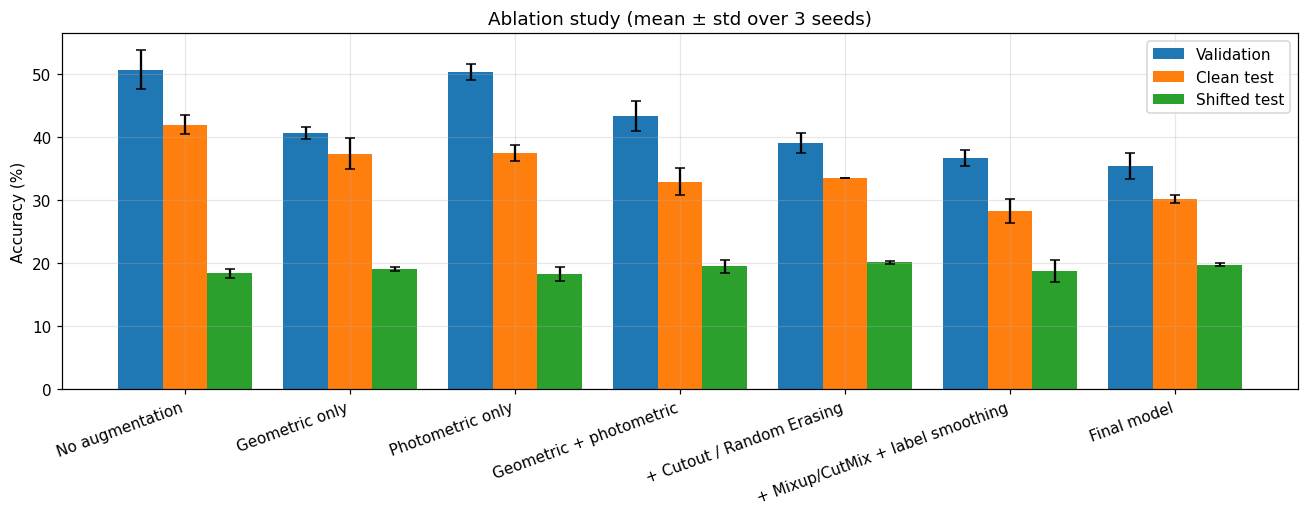

In [ ]:
# part D

for name in CFG_NAMES:
    run_config(name)

abl = pd.DataFrame([summary_row(n, keys=("val", "clean", "shifted")) for n in CFG_NAMES])
abl.columns = ["Configuration", "Val Acc", "Clean Test", "Shifted Test"]
display(abl)
abl.to_csv(f"{OUT_DIR}/ablation_table.csv", index=False)

def mean_std(name, k):
    v = np.array([RESULTS[name][s][k] for s in RESULTS[name]]); return v.mean(), v.std()

fig, ax = plt.subplots(figsize=(12, 4.8)); w = 0.27; xs = np.arange(len(CFG_NAMES))
for j, (k, lab) in enumerate([("val", "Validation"), ("clean", "Clean test"), ("shifted", "Shifted test")]):
    ms = np.array([mean_std(n, k) for n in CFG_NAMES])
    ax.bar(xs + (j - 1) * w, ms[:, 0], w, yerr=ms[:, 1], capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels([n.split(" (")[0] for n in CFG_NAMES], rotation=20, ha="right")
ax.set(ylabel="Accuracy (%)", title="Ablation study (mean ± std over 3 seeds)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/partD_ablation.png", bbox_inches="tight"); plt.show()

In [13]:
# Gain on the shifted test of each augmentation family relative to its natural reference
sh = {n: mean_std(n, "shifted")[0] for n in CFG_NAMES}
gains = {
    "Geometric (crop, flip, rotation)":     sh["Geometric only (crop, flip, rotation)"] - sh["No augmentation"],
    "Photometric (color jitter, blur, noise)": sh["Photometric only (color jitter, blur, noise)"] - sh["No augmentation"],
    "Cutout / Random Erasing":              sh["+ Cutout / Random Erasing"] - sh["Geometric + photometric"],
    "Mixup/CutMix + label smoothing":       sh["+ Mixup/CutMix + label smoothing"] - sh["+ Cutout / Random Erasing"],
    "Random grayscale (final model)":       sh["Final model"] - sh["+ Mixup/CutMix + label smoothing"],
}
gdf = pd.DataFrame({"Augmentation": list(gains), "Shifted-test gain (pts)": np.round(list(gains.values()), 2)})
display(gdf.sort_values("Shifted-test gain (pts)", ascending=False))

MATCH = {
    "Geometric (crop, flip, rotation)": "the ±25° ROTATION in the shifted test: the model has seen rotated, shifted and rescaled "
        "objects, so its filters respond to the object at different orientations instead of one canonical pose",
    "Photometric (color jitter, blur, noise)": "the BRIGHTNESS/CONTRAST changes (and blur/noise) in the shifted test: "
        "the model no longer relies on absolute intensity or colour, which is exactly what the darkening/brightening destroys",
    "Cutout / Random Erasing": "the ~25% RECTANGULAR OCCLUSION in the shifted test: random erasing is nearly the same "
        "operation, so the network learns to classify from the parts of the object that remain visible",
    "Mixup/CutMix + label smoothing": "the OVERFITTING part of the failure (and CutMix also resembles occlusion): "
        "mixed images and soft labels stop memorisation of the 400 images",
    "Random grayscale (final model)": "the COLOUR-type corruptions (including the hidden one): forcing shape-based "
        "features makes the model less sensitive to colour changes",
}
BEST_CHANGE = max(gains, key=gains.get)
print(f"Largest single gain on the shifted test: {BEST_CHANGE}  (+{gains[BEST_CHANGE]:.2f} pts)")
print("Why: it matches " + MATCH[BEST_CHANGE] + ".")

,Augmentation,Shifted-test gain (pts)
4,Random grayscale (final model),0.98
0,"Geometric (crop, flip, rotation)",0.76
2,Cutout / Random Erasing,0.65
1,"Photometric (color jitter, blur, noise)",-0.13
3,Mixup/CutMix + label smoothing,-1.38


Largest single gain on the shifted test: Random grayscale (final model)  (+0.98 pts)
Why: it matches the COLOUR-type corruptions (including the hidden one): forcing shape-based features makes the model less sensitive to colour changes.


**What the ablation shows.**
Measured step by step on the shifted test, the largest single gain came from adding **random grayscale** in the final model (+0.98 points), followed by geometric augmentation (+0.76) and Random Erasing (+0.65). Photometric augmentation on its own (−0.13) and Mixup/CutMix with label smoothing (−1.38) did not help.

Grayscale matches the colour side of the shifted test. About half of the shifted images have their colour channels swapped (the hidden corruption), and all of them have brightness and contrast changes. Grayscale teaches the network not to trust exact colour and to rely on shape instead, and shape is what survives these corruptions. Random Erasing is the closest match to the ~25 % rectangular occlusion, and it gave the highest absolute shifted score of all rows (20.11 ± 0.22).

Two honest caveats. First, every gain is around 1 point, which is close to the standard deviation across seeds, so these are small trends rather than firm results. Second, validation accuracy goes down as augmentation increases (50.7 % → 35.3 %), because a clean validation split cannot measure robustness to corruption. For that reason the `Final model` was defined in advance as the complete augmentation pipeline, and the test scores were never used to change it.

Final model seed chosen by validation: 1
Shifted test 19.38% | clean test 29.54%


,class,clean acc (%),shifted acc (%),drop
0,airplane,27.1,30.0,-2.9
1,automobile,68.3,29.1,39.2
2,bird,15.6,9.9,5.7
3,cat,30.1,40.3,-10.2
4,deer,24.5,17.7,6.8
5,dog,23.3,8.0,15.3
6,frog,24.3,13.0,11.3
7,horse,14.5,5.8,8.7
8,ship,64.4,36.4,28.0
9,truck,3.3,3.6,-0.3


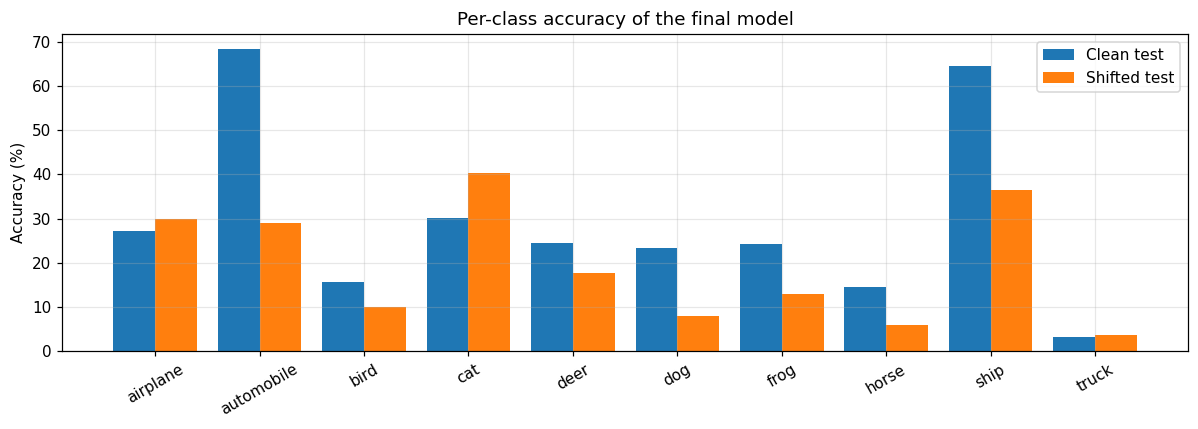

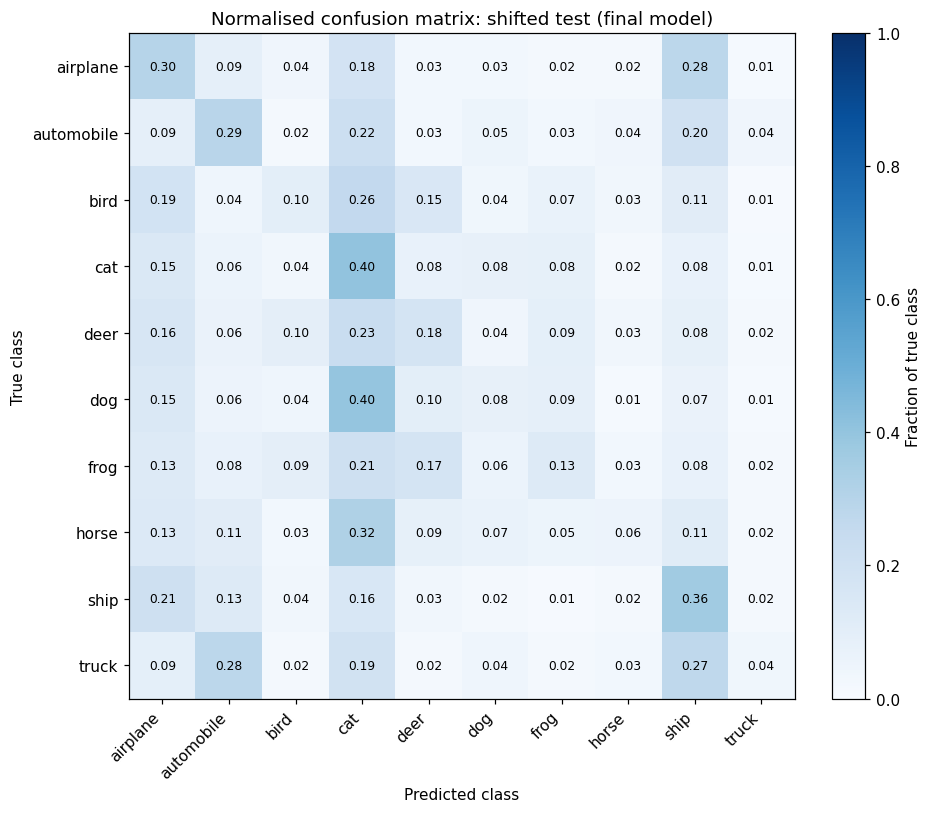

In [ ]:
# part E


FINAL = "Final model"
best_seed = max(RESULTS[FINAL], key=lambda s: (RESULTS[FINAL][s]["val"], -RESULTS[FINAL][s]["best_epoch"]))
final_model = load_model(FINAL, int(best_seed))
print("Final model seed chosen by validation:", best_seed)

acc_sh, _, pred_sh, prob_sh = evaluate(final_model, X_shift, y_shift)
acc_cl, _, pred_cl, prob_cl = evaluate(final_model, X_test_clean, y_test)
print(f"Shifted test {acc_sh:.2f}% | clean test {acc_cl:.2f}%")

# E.1 per-class accuracy
pc = pd.DataFrame({"class": CLASSES,
                   "clean acc (%)":   [100 * (pred_cl[y_test == c] == c).float().mean().item() for c in range(10)],
                   "shifted acc (%)": [100 * (pred_sh[y_shift == c] == c).float().mean().item() for c in range(10)]})
pc["drop"] = pc["clean acc (%)"] - pc["shifted acc (%)"]
display(pc.round(1))

fig, ax = plt.subplots(figsize=(11, 4)); xs = np.arange(10)
ax.bar(xs - 0.2, pc["clean acc (%)"], 0.4, label="Clean test"); ax.bar(xs + 0.2, pc["shifted acc (%)"], 0.4, label="Shifted test")
ax.set_xticks(xs); ax.set_xticklabels(CLASSES, rotation=30)
ax.set(ylabel="Accuracy (%)", title="Per-class accuracy of the final model"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/partE_per_class.png", bbox_inches="tight"); plt.show()

# normalised confusion matrix (rows = true class)
cm = confusion_matrix(y_shift.numpy(), pred_sh.numpy(), labels=range(10), normalize="true")
fig, ax = plt.subplots(figsize=(8.5, 7.5)); im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
ax.set(xlabel="Predicted class", ylabel="True class", title="Normalised confusion matrix: shifted test (final model)")
ax.grid(False); plt.colorbar(im, fraction=0.046, label="Fraction of true class")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/partE_confusion_matrix.png", bbox_inches="tight"); plt.show()

In [15]:
# E.2 most confused pairs (off-diagonal)
pairs = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(10) for j in range(10) if i != j]
top = pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:8], columns=["true", "predicted", "fraction of true class"])
display(top.round(3))

,true,predicted,fraction of true class
0,dog,cat,0.397
1,horse,cat,0.324
2,airplane,ship,0.280
3,truck,automobile,0.279
4,truck,ship,0.273
5,bird,cat,0.259
6,deer,cat,0.233
7,automobile,cat,0.216


**Which classes are confused most, and why.**
The biggest confusions on the shifted test are dog → cat (39.7 % of all dogs), horse → cat (32.4 %), airplane → ship (28.0 %), truck → automobile (27.9 %), truck → ship (27.3 %), bird → cat (25.9 %) and deer → cat (23.3 %).

* **Cat has become the default animal class.** When occlusion, blur or noise remove the details, dogs, horses, birds and deer all end up as cat. That is why cat is the only class whose accuracy goes *up* on the shifted test (30.1 % → 40.3 %).
* **Dog vs cat** is the classic pair: same size, fur, pose and indoor backgrounds. At 32×32 the snout and ears that separate them are only a few pixels wide, and the occlusion box often hides them.
* **Airplane and truck → ship:** when the object is hidden or recoloured, the large flat background (sky, water, road) decides the prediction. A channel swap can also turn brown ground or green grass blue, which looks like water.
* **Truck vs automobile:** both are vehicles with wheels and windows. Once the box covers the cargo area, a truck looks like a car. Truck is the weakest class overall (3.3 % clean), so the model rarely predicts it at all.

With only 40 training images per class, the model leans heavily on colour and background, and those are exactly the cues the corruptions change.

,test idx,true,predicted,confidence,clean image correct?,likely cause
0,6303,horse,ship,0.533,False,"colour channels swapped, occlusion covers obje..."
1,3903,airplane,ship,0.521,False,"colour channels swapped, very bright / washed ..."
2,609,truck,automobile,0.519,False,also wrong on CLEAN image → intrinsic class si...
3,3850,truck,automobile,0.511,False,"colour channels swapped, occlusion covers obje..."
4,6910,horse,ship,0.498,False,"colour channels swapped, occlusion covers obje..."
5,257,airplane,ship,0.498,False,"colour channels swapped, noisy, also wrong on ..."
6,7560,airplane,ship,0.494,False,"colour channels swapped, occlusion covers obje..."
7,8469,dog,automobile,0.491,False,"occlusion covers object centre, also wrong on ..."
8,6419,truck,ship,0.486,False,"occlusion covers object centre, also wrong on ..."
9,7139,airplane,ship,0.485,False,"occlusion covers object centre, blurred, also ..."


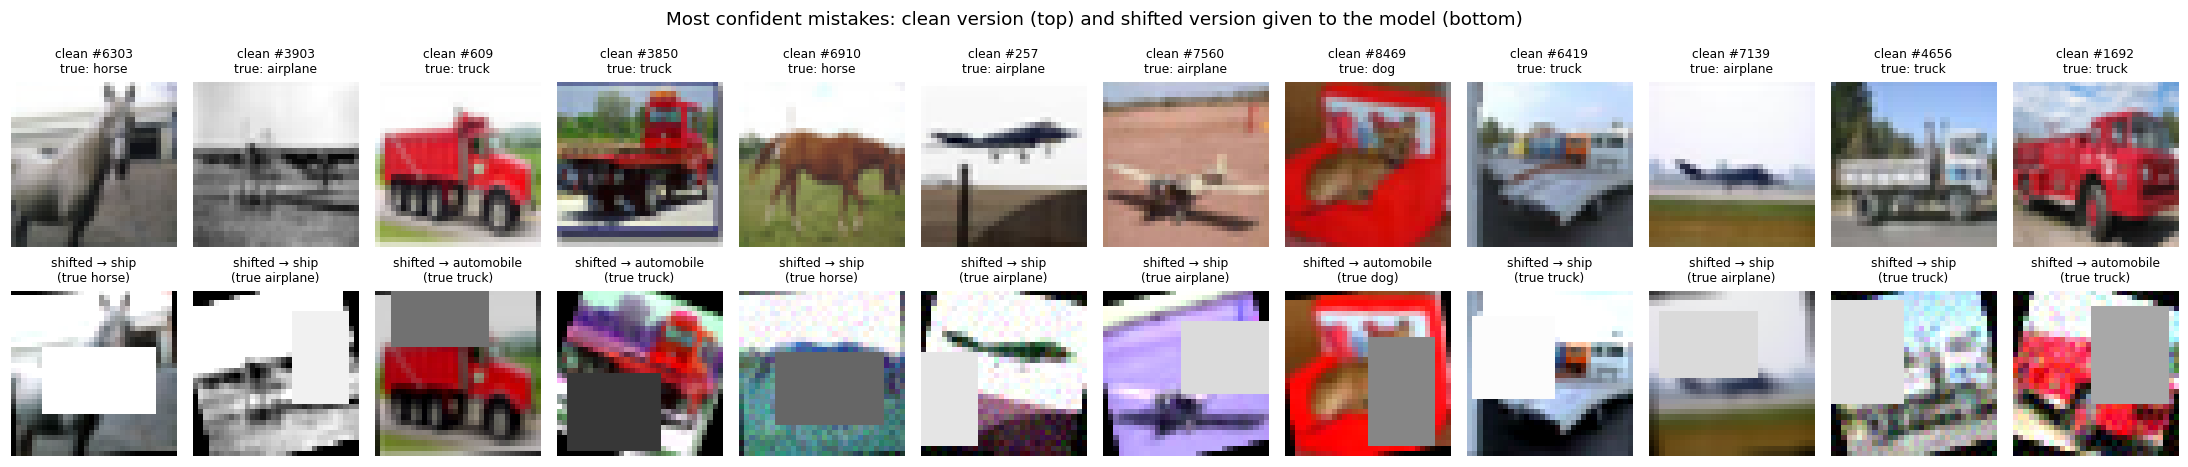

In [16]:
# E.3 misclassified images: most confident mistakes on the shifted test
wrong = torch.where(pred_sh != y_shift)[0]
conf = prob_sh[wrong, pred_sh[wrong]]
order = torch.argsort(conf, descending=True)[:12]
sel, sel_conf = wrong[order].tolist(), conf[order].tolist()

def likely_cause(i):
    if shift_meta is None: return "see image"
    m = shift_meta.iloc[i]; causes = []
    if m["channel_swap"]: causes.append("colour channels swapped")
    y0, x0, h, w = m["occ_box"]
    if (y0 < 20 and y0 + h > 12 and x0 < 20 and x0 + w > 12) and m["occ_frac"] > 0.2: causes.append("occlusion covers object centre")
    if abs(m["angle"]) > 18: causes.append(f"strong rotation ({m['angle']:.0f}°)")
    if m["brightness"] < 0.65: causes.append("very dark")
    if m["brightness"] > 1.35: causes.append("very bright / washed out")
    if m["contrast"] < 0.7: causes.append("low contrast")
    if m["blur"]: causes.append("blurred")
    if m["noise"]: causes.append("noisy")
    if pred_cl[i] != y_test[i]: causes.append("also wrong on CLEAN image → intrinsic class similarity")
    return ", ".join(causes) if causes else "intrinsic similarity / unusual pose or background"

rows = []
for i, c in zip(sel, sel_conf):
    rows.append({"test idx": i, "true": CLASSES[y_shift[i]], "predicted": CLASSES[pred_sh[i]],
                 "confidence": round(c, 3), "clean image correct?": bool(pred_cl[i] == y_test[i]),
                 "likely cause": likely_cause(i)})
mis = pd.DataFrame(rows); display(mis)
mis.to_csv(f"{OUT_DIR}/partE_misclassified.csv", index=False)

show_grid([X_test_clean[i] for i in sel] + [X_shift[i] for i in sel],
          [f"clean #{i}\ntrue: {CLASSES[y_test[i]]}" for i in sel] +
          [f"shifted → {CLASSES[pred_sh[i]]}\n(true {CLASSES[y_shift[i]]})" for i in sel],
          nrow=2, ncol=12, figsize=(20, 4.5),
          suptitle="Most confident mistakes: clean version (top) and shifted version given to the model (bottom)",
          fname="partE_misclassified.png")

**Explaining the failures.** These are the 12 most confident mistakes of the final model on the shifted test. The corruption settings come from `shift_meta`. All 12 images were also misclassified in their clean version, so they were already hard; the corruptions then pushed the model further towards the wrong class.

**Image 6303 (horse to ship):** the red and blue channels were swapped, and a box hid 28% of the image over the horse's body. Only the head and a pale background remained, which look like sky or sea, so the model predicted ship.

**Image 3903 (airplane to ship):** the image was made very bright (×1.49), rotated by 12° and had its channels swapped, with a box on the right side. The washed-out image kept only a horizon line, and the fuselage looked like the hull of a ship.

**Image 609 (truck to automobile):** the image was darkened (×0.74), and a dark box covered the top of the truck. What was left was a red body with wheels, which is exactly what a car looks like.

**Image 3850 (truck to automobile):** the image was rotated by −20°, the channels were swapped so the red truck turned purple, and a box covered the wheels. Tilted, recoloured and with its lower part hidden, the truck lost the shape cues that separate it from a car.

**Image 6910 (horse to ship):** noise was added, the channel swap turned the green grass blue, and a box covered 29% of the image over the body. The bluish, noisy texture looked like water, and the horse itself was hidden.

**Image 257 (airplane to ship):** noise was added, the image was rotated by −11°, the channels were swapped, and a box covered the lower left. The plane now sat above a strip that looked like a water line.

**Image 7560 (airplane to ship):** the image was made very bright (×1.31), the channel swap turned the brown runway purple-blue, and a box covered one wing. The runway now looked like water and the wing outline was gone.

**Image 8469 (dog to automobile):** a box hid half of the dog, which was lying on a large red chair. The big red shape matched the red cars in the training set.

**Image 6419 (truck to ship):** a box hid the front and the cab of the truck (25%). The remaining long silver body against a light sky looked like a boat.

**Image 7139 (airplane to ship):** the image was blurred and a box covered most of the plane. Only the sky and a horizon remained, which is a typical ship background.

**Image 4656 (truck to ship):** noise was added, the image was rotated by 13°, and a box covered the front of the truck. Mostly sky was left, and the noise removed the edges of the vehicle.

**Image 1692 (truck to automobile):** the image was made very bright (×1.44), noise was added, it was rotated by −15°, and a box covered the rear. Only the red front was visible, which looks like a car.

The recurring visual causes are the occlusion box hiding the discriminative part, channel swaps turning backgrounds blue, strong brightness changes washing out edges, and intrinsic similarity between classes such as truck and automobile or dog and cat.

,Configuration,Clean test,Hidden corruption only,Drop (pts)
0,No augmentation,41.94 ± 1.45,29.23 ± 0.86,12.71
1,Geometric + photometric,32.90 ± 2.18,19.37 ± 1.05,13.53
2,+ Mixup/CutMix + label smoothing,28.19 ± 1.90,15.81 ± 1.19,12.38
3,Final model,30.15 ± 0.58,18.15 ± 0.06,12.00


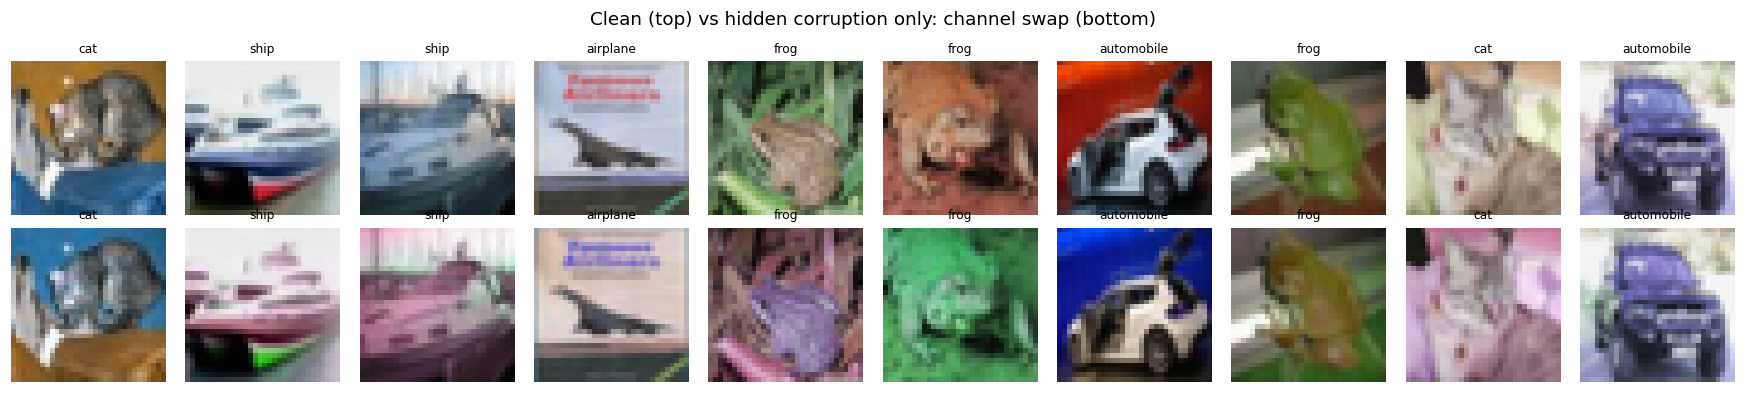

In [17]:
# E.4 Hidden-corruption test: apply ONLY the unlisted corruption (channel permutation) to the clean test set
rng_h = np.random.default_rng(7)
X_hidden = torch.stack([to_uint8(hidden_corruption(X_test_clean[i].float() / 255., rng_h)[0]) for i in range(len(X_test_clean))])

rows = []
for name in ["No augmentation", "Geometric + photometric", "+ Mixup/CutMix + label smoothing", "Final model"]:
    cl, hd = [], []
    for s in RESULTS[name]:
        m = load_model(name, int(s)); cl.append(evaluate(m, X_test_clean, y_test)[0]); hd.append(evaluate(m, X_hidden, y_test)[0])
    rows.append({"Configuration": name, "Clean test": f"{np.mean(cl):.2f} ± {np.std(cl):.2f}",
                 "Hidden corruption only": f"{np.mean(hd):.2f} ± {np.std(hd):.2f}",
                 "Drop (pts)": round(np.mean(cl) - np.mean(hd), 2)})
hidden_df = pd.DataFrame(rows); display(hidden_df)
show_grid([X_test_clean[i] for i in range(10)] + [X_hidden[i] for i in range(10)],
          [CLASSES[y_test[i]] for i in range(10)] * 2, suptitle="Clean (top) vs hidden corruption only: channel swap (bottom)",
          fname="partE_hidden_corruption.png")

**Did the augmentation generalise to the hidden corruption?**
None of the training configurations uses channel swapping, so this measures how well invariance *transfers*, not memorisation of the test pipeline.

Only a little. The final model has the smallest drop (12.00 points, against 12.71 for the baseline) and by far the most stable result across seeds (±0.06), so random grayscale and colour jitter helped slightly. But every model still loses 12 to 13 points, and the baseline keeps the highest absolute accuracy (29.23 %) because it starts from a higher clean score.

The reason is that the augmentations are much weaker than the corruption. A hue jitter of ±0.05 is tiny compared with a full channel permutation, and grayscale removes colour rather than showing the network what swapped colours look like. Real robustness would need much stronger colour augmentation (a large hue range, channel shuffling, AugMix-style mixing). Adding channel shuffling here, however, would mean copying the hidden corruption, which the assignment does not allow.

In [ ]:
# part

SHIFTS = [(0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)]

def tta_views(xb):
    pad = F.pad(xb, (2, 2, 2, 2), mode="reflect"); views = []
    for flip in (False, True):
        p = torch.flip(pad, dims=[3]) if flip else pad
        for dy, dx in SHIFTS:
            views.append(p[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx])
    return views

def tta_predict(model, xb):
    return torch.stack([F.softmax(model(v), 1) for v in tta_views(xb)]).mean(0)

def timed_eval(model, X, y, tta_fn=None):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time(); acc = evaluate(model, X, y, tta_fn=tta_fn)[0]
    if DEVICE == "cuda": torch.cuda.synchronize()
    return acc, time.time() - t0

rows = []
for s in RESULTS[FINAL]:
    m = load_model(FINAL, int(s))
    a0, t0 = timed_eval(m, X_shift, y_shift); a1, t1 = timed_eval(m, X_shift, y_shift, tta_predict)
    c0, _ = timed_eval(m, X_test_clean, y_test); c1, _ = timed_eval(m, X_test_clean, y_test, tta_predict)
    rows.append(dict(seed=s, shifted=a0, shifted_tta=a1, clean=c0, clean_tta=c1, time=t0, time_tta=t1))
tta = pd.DataFrame(rows); display(tta.round(2))
n = len(X_shift)
print(f"Shifted test: {tta.shifted.mean():.2f} ± {tta.shifted.std(ddof=0):.2f}  →  with TTA {tta.shifted_tta.mean():.2f} ± "
      f"{tta.shifted_tta.std(ddof=0):.2f}  (change {tta.shifted_tta.mean()-tta.shifted.mean():+.2f} pts)")
print(f"Clean test:   {tta.clean.mean():.2f}  →  with TTA {tta.clean_tta.mean():.2f}")
print(f"Inference cost: {1000*tta.time.mean()/n:.3f} ms/image → {1000*tta.time_tta.mean()/n:.3f} ms/image "
      f"(×{tta.time_tta.mean()/tta.time.mean():.1f} time, ×{len(tta_views(torch.zeros(1,3,32,32)))} forward passes)")

,seed,shifted,shifted_tta,clean,clean_tta,time,time_tta
0,0,19.96,19.75,30.93,30.93,1.15,11.56
1,1,19.38,19.25,29.54,29.58,1.15,11.68
2,2,19.80,19.81,29.97,29.97,1.20,12.09


Shifted test: 19.71 ± 0.24  →  with TTA 19.60 ± 0.25  (change -0.11 pts)
Clean test:   30.15  →  with TTA 30.16
Inference cost: 0.117 ms/image → 1.178 ms/image (×10.1 time, ×10 forward passes)


**Discussion.** With N = 10 views, shifted-test accuracy went from 19.71 ± 0.24 % to 19.60 ± 0.25 % (−0.11 points), and clean-test accuracy stayed practically the same (30.15 % → 30.16 %). Inference time rose from 0.117 to 1.178 ms per image, about 10× more, because every view needs its own forward pass.
TTA did not help here because flips and ±2-pixel shifts do not undo the real corruptions (occlusion, rotation, colour swap). For this test set it is not worth ten times the compute.